<a href="https://colab.research.google.com/github/somayaakter0324/Liver-Disease-Prediction/blob/main/STA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
#===================================
# Md Sharzil Karim (2024100000402)
#===================================
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# ============================================================
# CELL 1: Setup & Load Dataset
# ============================================================

# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

# Load Dataset
df = pd.read_csv('/content/drive/MyDrive/indian_liver_patient.csv')

# Rename columns
df.rename(columns={
    'Alamine_Aminotransferase':  'SGPT',
    'Aspartate_Aminotransferase': 'SGOT',
    'Total_Protiens':             'TotalProteins',
    'Albumin_and_Globulin_Ratio': 'AlbuminGlobulinRatio',
    'Alkaline_Phosphotase':       'AlkalinePhosphotase'
}, inplace=True)

# Map LiverDisease column
df['LiverDisease'] = df['Dataset'].map({1: 1, 2: 0})

# Define total_patients globally
total_patients = len(df)

print("Dataset loaded successfully!")
print(f"Shape: {df.shape}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dataset loaded successfully!
Shape: (583, 12)


In [ ]:
# ============================================================
# CELL 2: Question 1 — Dataset Structure & Identification
# ============================================================

print(f"Total Observations (Rows) : {df.shape[0]}")
print(f"Total Variables  (Columns): {df.shape[1]}")

print("\nVariable Names and Data Types:")
print("-" * 45)
print(f"{'Variable':<30} {'Data Type'}")
print("-" * 45)
for col, dtype in df.dtypes.items():
    print(f" {col:<29} {str(dtype)}")

print("\nFirst 5 Rows:")
df.head()

Total Observations (Rows) : 583
Total Variables  (Columns): 12

Variable Names and Data Types:
---------------------------------------------
Variable                       Data Type
---------------------------------------------
 Age                           int64
 Gender                        object
 Total_Bilirubin               float64
 Direct_Bilirubin              float64
 AlkalinePhosphotase           int64
 SGPT                          int64
 SGOT                          int64
 TotalProteins                 float64
 Albumin                       float64
 AlbuminGlobulinRatio          float64
 Dataset                       int64
 LiverDisease                  int64

First 5 Rows:


,Age,Gender,Total_Bilirubin,Direct_Bilirubin,AlkalinePhosphotase,SGPT,SGOT,TotalProteins,Albumin,AlbuminGlobulinRatio,Dataset,LiverDisease
0,65,Female,0.7,0.1,187,16,18,6.8,3.3,0.90,1,1
1,62,Male,10.9,5.5,699,64,100,7.5,3.2,0.74,1,1
2,62,Male,7.3,4.1,490,60,68,7.0,3.3,0.89,1,1
3,58,Male,1.0,0.4,182,14,20,6.8,3.4,1.00,1,1
4,72,Male,3.9,2.0,195,27,59,7.3,2.4,0.40,1,1


In [ ]:
from google.colab import sheets
sheet = sheets.InteractiveSheet(df=df)

https://docs.google.com/spreadsheets/d/1GwJfqkR1SOMklyNSemEInnrWfVsvcM48G69PuWKBAQQ/edit#gid=0


In [ ]:
# ============================================================
# CELL 3: Question 2 & 3 — Descriptive Stats + Missing Values
# ============================================================

# --- Question 2: Descriptive Statistics ---
variables = ['Total_Bilirubin', 'Direct_Bilirubin', 'Albumin', 'AlkalinePhosphotase']

print("QUESTION 2: Descriptive Statistics")
print("=" * 55)
for var in variables:
    data = df[var].dropna()
    print(f"\n Variable: {var}")
    print(f"  Mean              : {data.mean():.4f}")
    print(f"  Median            : {data.median():.4f}")
    print(f"  Mode              : {data.mode()[0]:.4f}")
    print(f"  Variance          : {data.var():.4f}")
    print(f"  Standard Deviation: {data.std():.4f}")

# --- Question 3: Missing Values & Outliers ---
print("\n\nQUESTION 3: Missing Values & Outliers")
print("=" * 55)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nOutlier Detection (IQR Method):")
for var in ['Total_Bilirubin', 'Albumin', 'SGPT', 'SGOT']:
    data = df[var].dropna()
    Q1  = data.quantile(0.25)
    Q3  = data.quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    outliers = data[(data < lower) | (data > upper)]
    print(f"\n {var}:")
    print(f"  Q1={Q1:.2f}, Q3={Q3:.2f}, IQR={IQR:.2f}")
    print(f"  Lower={lower:.2f}, Upper={upper:.2f}")
    print(f"  Outliers: {len(outliers)} ({len(outliers)/len(data)*100:.1f}%)")
    print(f"  Max value: {data.max():.2f}")

QUESTION 2: Descriptive Statistics

 Variable: Total_Bilirubin
  Mean              : 3.2988
  Median            : 1.0000
  Mode              : 0.8000
  Variance          : 38.5582
  Standard Deviation: 6.2095

 Variable: Direct_Bilirubin
  Mean              : 1.4861
  Median            : 0.3000
  Mode              : 0.2000
  Variance          : 7.8877
  Standard Deviation: 2.8085

 Variable: Albumin
  Mean              : 3.1419
  Median            : 3.1000
  Mode              : 3.0000
  Variance          : 0.6329
  Standard Deviation: 0.7955

 Variable: AlkalinePhosphotase
  Mean              : 290.5763
  Median            : 208.0000
  Mode              : 198.0000
  Variance          : 59018.8666
  Standard Deviation: 242.9380


QUESTION 3: Missing Values & Outliers

Missing Values:
Age                     0
Gender                  0
Total_Bilirubin         0
Direct_Bilirubin        0
AlkalinePhosphotase     0
SGPT                    0
SGOT                    0
TotalProteins           

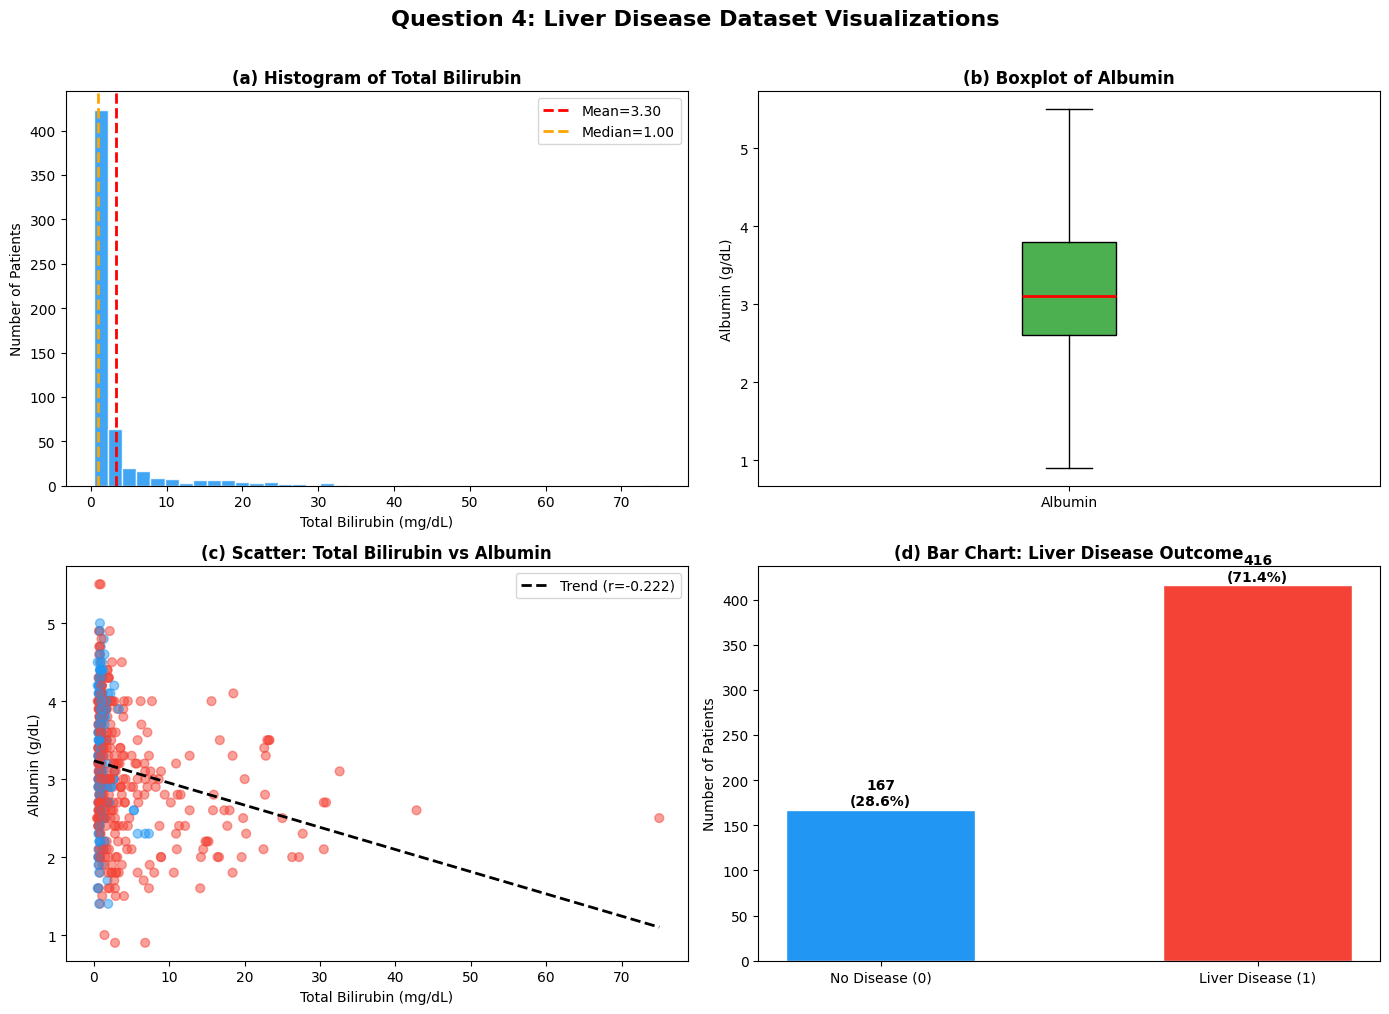

All 4 visualizations saved!


In [ ]:
# ============================================================
# CELL 4: Question 4 — Visualizations
# ============================================================

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('Question 4: Liver Disease Dataset Visualizations',
             fontsize=16, fontweight='bold', y=1.01)

# (a) Histogram of Total Bilirubin
axes[0,0].hist(df['Total_Bilirubin'], bins=40,
               color='#2196F3', edgecolor='white', alpha=0.85)
axes[0,0].axvline(df['Total_Bilirubin'].mean(),
                  color='red', ls='--', lw=2,
                  label=f"Mean={df['Total_Bilirubin'].mean():.2f}")
axes[0,0].axvline(df['Total_Bilirubin'].median(),
                  color='orange', ls='--', lw=2,
                  label=f"Median={df['Total_Bilirubin'].median():.2f}")
axes[0,0].set_title('(a) Histogram of Total Bilirubin', fontweight='bold')
axes[0,0].set_xlabel('Total Bilirubin (mg/dL)')
axes[0,0].set_ylabel('Number of Patients')
axes[0,0].legend()

# (b) Boxplot of Albumin
axes[0,1].boxplot(df['Albumin'].dropna(), patch_artist=True,
                  boxprops=dict(facecolor='#4CAF50'),
                  medianprops=dict(color='red', linewidth=2))
axes[0,1].set_title('(b) Boxplot of Albumin', fontweight='bold')
axes[0,1].set_ylabel('Albumin (g/dL)')
axes[0,1].set_xticks([1])
axes[0,1].set_xticklabels(['Albumin'])

# (c) Scatter Plot: Total Bilirubin vs Albumin
colors = df['LiverDisease'].map({1: '#F44336', 0: '#2196F3'})
axes[1,0].scatter(df['Total_Bilirubin'], df['Albumin'],
                  c=colors, alpha=0.5, s=40)
m, b, r, _, _ = stats.linregress(df['Total_Bilirubin'], df['Albumin'])
x_line = np.linspace(0, df['Total_Bilirubin'].max(), 200)
axes[1,0].plot(x_line, m*x_line+b, 'k--', lw=2,
               label=f'Trend (r={r:.3f})')
axes[1,0].set_title('(c) Scatter: Total Bilirubin vs Albumin', fontweight='bold')
axes[1,0].set_xlabel('Total Bilirubin (mg/dL)')
axes[1,0].set_ylabel('Albumin (g/dL)')
axes[1,0].legend()

# (d) Bar Chart: Liver Disease Outcome
counts = df['LiverDisease'].value_counts().sort_index()
bars = axes[1,1].bar(['No Disease (0)', 'Liver Disease (1)'],
                     [counts[0], counts[1]],
                     color=['#2196F3', '#F44336'],
                     edgecolor='white', width=0.5)
for bar, count in zip(bars, [counts[0], counts[1]]):
    pct = count / len(df) * 100
    axes[1,1].text(bar.get_x() + bar.get_width()/2,
                   bar.get_height() + 5,
                   f'{count}\n({pct:.1f}%)',
                   ha='center', fontweight='bold')
axes[1,1].set_title('(d) Bar Chart: Liver Disease Outcome', fontweight='bold')
axes[1,1].set_ylabel('Number of Patients')

plt.tight_layout()
plt.savefig('section1_visualizations.png', dpi=150, bbox_inches='tight')
plt.show()
print("All 4 visualizations saved!")

Group Comparison: Liver Disease vs No Disease

 Variable                 Liver Disease     No Disease   Difference
 ───────────────────────────────────────────────────────────────
  Total_Bilirubin                4.1644         1.1425      +3.0219
  Albumin                        3.0606         3.3443      -0.2837
  SGPT                          99.6058        33.6527     +65.9531
  SGOT                         137.6995        40.6886     +97.0109


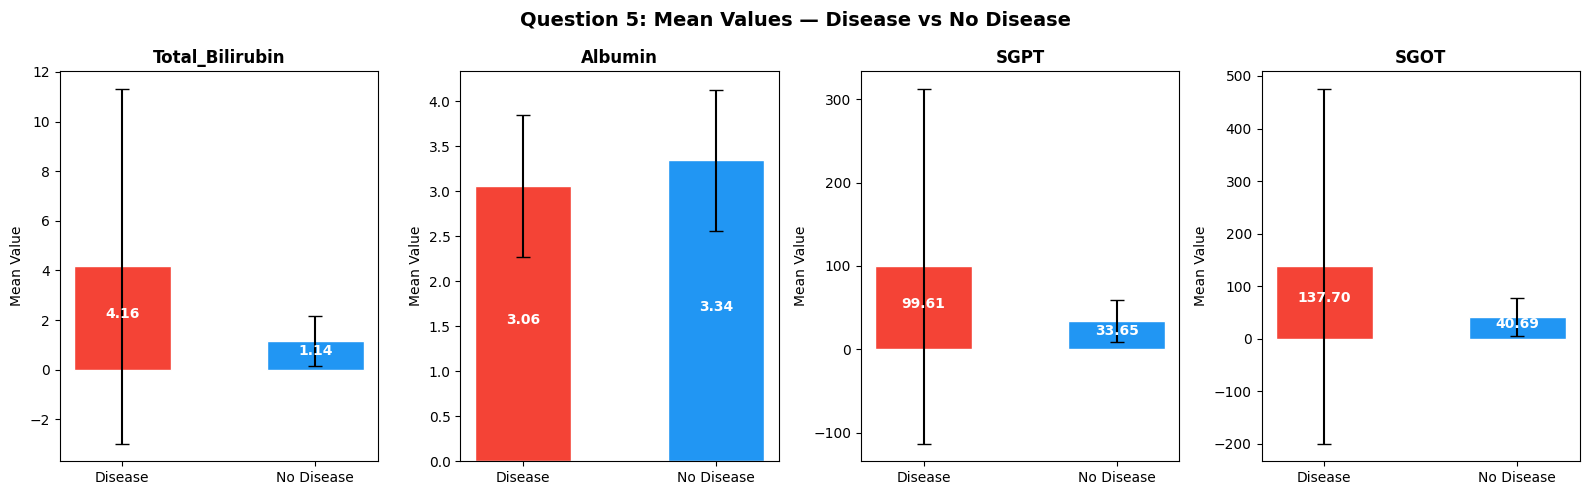

Question 5 chart saved!


In [ ]:
# ============================================================
# CELL 5: Question 5 — Disease vs Non-Disease Comparison
# ============================================================

disease    = df[df['LiverDisease'] == 1]
no_disease = df[df['LiverDisease'] == 0]

compare_vars = ['Total_Bilirubin', 'Albumin', 'SGPT', 'SGOT']

print("Group Comparison: Liver Disease vs No Disease")
print("=" * 65)
print(f"\n {'Variable':<22} {'Liver Disease':>15} {'No Disease':>14} {'Difference':>12}")
print(" " + "─" * 63)
for var in compare_vars:
    m1   = disease[var].mean()
    m0   = no_disease[var].mean()
    diff = m1 - m0
    print(f"  {var:<22} {m1:>14.4f} {m0:>14.4f} {diff:>+12.4f}")

# Bar chart comparison
fig, axes = plt.subplots(1, 4, figsize=(16, 5))
fig.suptitle('Question 5: Mean Values — Disease vs No Disease',
             fontsize=14, fontweight='bold')

for i, var in enumerate(compare_vars):
    means  = [disease[var].mean(), no_disease[var].mean()]
    errors = [disease[var].std(),  no_disease[var].std()]
    bars = axes[i].bar(['Disease', 'No Disease'], means,
                       color=['#F44336', '#2196F3'],
                       edgecolor='white', width=0.5,
                       yerr=errors, capsize=5)
    axes[i].set_title(var, fontweight='bold')
    axes[i].set_ylabel('Mean Value')
    for bar, val in zip(bars, means):
        axes[i].text(bar.get_x() + bar.get_width()/2,
                     bar.get_height() * 0.5,
                     f'{val:.2f}', ha='center',
                     color='white', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.savefig('section1_q5_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print("Question 5 chart saved!")

In [ ]:
#==========================================
#Ayman Nehar Siddiqa Sayma (202410000305)
#==========================================

#SECTION 2 -Probability, Probability Distribution & CLT
#Question 6
from scipy.stats import binom
print("--- QUESTION 6 ---")
# Using correct column names: 'Dataset' and 'Total_Bilirubin'
liver_disease_count = len(df[df['Dataset'] == 1])
high_b20_count = len(df[df['Total_Bilirubin'] > 2.0])
both_b20_and_liver = len(df[(df['Dataset'] == 1) & (df['Total_Bilirubin'] > 2.0)])

# Probability Calculations
P_L = liver_disease_count / total_patients
P_B = high_b20_count / total_patients
P_L_and_B = both_b20_and_liver / total_patients
P_L_given_B = P_L_and_B / P_B

print(f"P(L) [Probability of Liver Disease]: {P_L:.4f}")
print(f"P(B) [Probability of Total_Bilirubin > 2.0]: {P_B:.4f}")
print(f"P(L ∩ B) [Joint Probability]: {P_L_and_B:.4f}")
print(f"P(L | B) [Conditional Probability P(L|B)]: {P_L_given_B:.4f}")

--- QUESTION 6 ---


NameError: name 'df' is not defined

In [ ]:
#Question 7
from scipy.stats import binom
print("QUESTION 7 (Bayes' Theorem)")
total_patients = len(df)

# Liver disease count
liver_disease_count = len(df[df['Dataset'] == 1])

# Prior probability
P_L = liver_disease_count / total_patients
# Condition: Total_Bilirubin > 2.5
high_b25_count = len(df[df['Total_Bilirubin'] > 2.5])
b25_given_liver = len(df[(df['Dataset'] == 1) & (df['Total_Bilirubin'] > 2.5)]) / liver_disease_count

# Applying Bayes' Formula
P_B25 = high_b25_count / total_patients
P_L_given_B25 = (b25_given_liver * P_L) / P_B25

print(f"Prior Probability P(L): {P_L:.4f}")
print(f"Likelihood P(B_2.5 | L): {b25_given_liver:.4f}")
print(f"Posterior Probability P(L | B_2.5): {P_L_given_B25:.4f}")

QUESTION 7 (Bayes' Theorem)


NameError: name 'df' is not defined

In [ ]:
#Question 8
from scipy.stats import binom

print("QUESTION 8 (Binomial Distribution)")
n = 15
p = 0.42

# (a) Exactly 6 patients
prob_exact_6 = binom.pmf(6, n, p)

# (b) At least 7 patients
prob_at_least_7 = 1 - binom.cdf(6, n, p)

# (c) At most 5 patients
prob_at_most_5 = binom.cdf(5, n, p)

print(f"Probability of exactly 6 patients P(X = 6): {prob_exact_6:.4f}")
print(f"Probability of at least 7 patients P(X >= 7): {prob_at_least_7:.4f}")
print(f"Probability of at most 5 patients P(X <= 5): {prob_at_most_5:.4f}")

QUESTION 8 (Binomial Distribution)
Probability of exactly 6 patients P(X = 6): 0.2041
Probability of at least 7 patients P(X >= 7): 0.4530
Probability of at most 5 patients P(X <= 5): 0.3430


Q9 (1) P(X < 1.2) = 0.052
Q9 (2) P(1.2 < X < 3.5) = 0.842
Q9 (3) P(X > 4.0) = 0.03


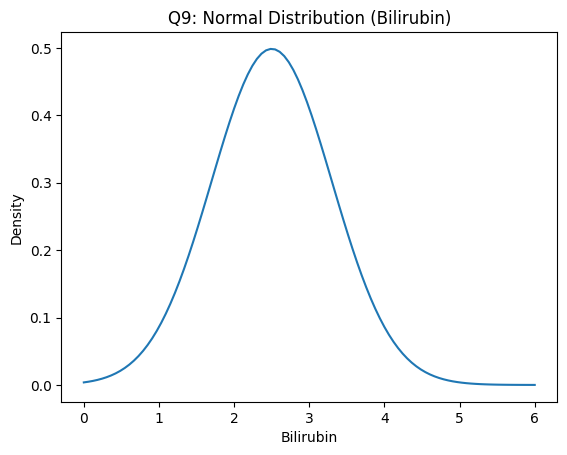

In [ ]:
#========================================
#Afia jainab (2024100000365)
#=========================================
# Q9 - Normal Distribution

from scipy.stats import norm
import numpy as np
import matplotlib.pyplot as plt

mu = 2.5
sigma = 0.8

# Probabilities
p1 = norm.cdf(1.2, mu, sigma)
p2 = norm.cdf(3.5, mu, sigma) - norm.cdf(1.2, mu, sigma)
p3 = 1 - norm.cdf(4.0, mu, sigma)

print("Q9 (1) P(X < 1.2) =", round(p1,3))
print("Q9 (2) P(1.2 < X < 3.5) =", round(p2,3))
print("Q9 (3) P(X > 4.0) =", round(p3,3))

# Graph
x = np.linspace(0, 6, 100)
y = norm.pdf(x, mu, sigma)

plt.plot(x, y)
plt.title("Q9: Normal Distribution (Bilirubin)")
plt.xlabel("Bilirubin")
plt.ylabel("Density")
plt.show()

Q10 PDF = 0.0167
Q10 P(35 < X < 55) = 0.333
Q10 Mean = 50.0
Q10 Variance = 300.0


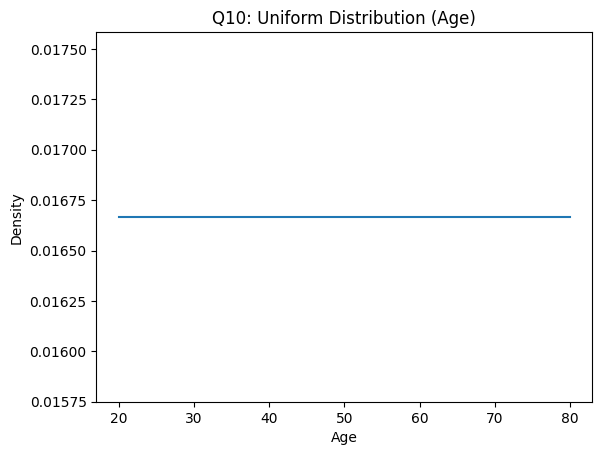

In [ ]:
# Q10 - Uniform Distribution

import numpy as np
import matplotlib.pyplot as plt

a = 20
b = 80

# Calculations
pdf = 1/(b-a)
p = (55-35)/(b-a)
mean = (a+b)/2
variance = ((b-a)**2)/12

print("Q10 PDF =", round(pdf,4))
print("Q10 P(35 < X < 55) =", round(p,3))
print("Q10 Mean =", mean)
print("Q10 Variance =", variance)

# Graph
x = np.linspace(a, b, 100)
y = [pdf]*100

plt.plot(x, y)
plt.title("Q10: Uniform Distribution (Age)")
plt.xlabel("Age")
plt.ylabel("Density")
plt.show()

Q11 P(X > 4) = 0.368
Q11 Expected Time = 4.0
Q11 Variance = 16.0


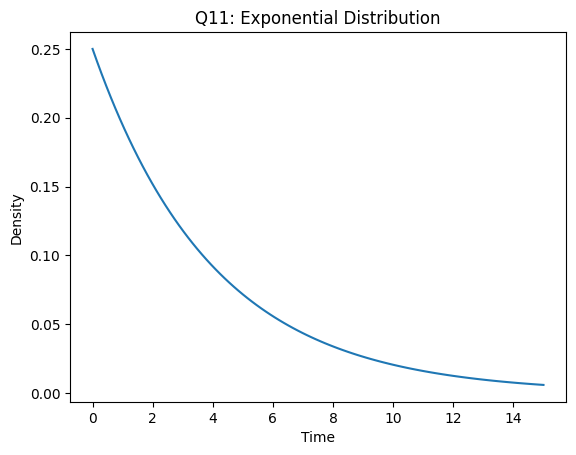

In [ ]:
# Q11 - Exponential Distribution

import numpy as np
import matplotlib.pyplot as plt

lam = 0.25

# Calculations
p = np.exp(-lam * 4)
mean = 1/lam
variance = 1/(lam**2)

print("Q11 P(X > 4) =", round(p,3))
print("Q11 Expected Time =", mean)
print("Q11 Variance =", variance)

# Graph
x = np.linspace(0, 15, 100)
y = lam * np.exp(-lam * x)

plt.plot(x, y)
plt.title("Q11: Exponential Distribution")
plt.xlabel("Time")
plt.ylabel("Density")
plt.show()

In [ ]:
# Q12 - Central Limit Theorem (CLT)

import scipy.stats as stats
import math

mu = 2.5
sigma = 0.8
n = 49

# Calculations
sample_mean = mu
se = sigma / math.sqrt(n)

z = (2.7 - mu) / se
p = 1 - stats.norm.cdf(z)

print("Q12 Sampling Mean =", sample_mean)
print("Q12 Standard Error =", round(se,3))
print("Q12 P(X̄ > 2.7) =", round(p,3))

Q12 Sampling Mean = 2.5
Q12 Standard Error = 0.114
Q12 P(X̄ > 2.7) = 0.04


In [ ]:
#=============================================
#Miss. Somaya Akter (2024100000324 )
#=============================================
#SECTION 3 -Confidence Interval & Hypothesis Testing
#Question 13
# Given values
mean = 2.8
std = 0.9
n = 64

# Standard Error
se = std / np.sqrt(n)

# Z value for 95%
z = 1.96

# Confidence Interval
lower = mean - z * se
upper = mean + z * se

print("95% Confidence Interval for Bilirubin:")
print("Lower Limit:", round(lower, 3))
print("Upper Limit:", round(upper, 3))

95% Confidence Interval for Bilirubin:
Lower Limit: 2.58
Upper Limit: 3.02


In [ ]:
#Question 14
# Given values
mean_sample = 3.6
mu = 4.0
std = 0.7
n = 49

# Standard Error
se = std / np.sqrt(n)

# Z-statistic
z = (mean_sample - mu) / se

# Critical value (left-tailed, alpha=0.05)
z_critical = -1.645

print("Z value:", round(z, 3))
print("Critical value:", z_critical)

# Decision
if z < z_critical:
    print("Reject H0")
else:
    print("Fail to Reject H0")

Z value: -4.0
Critical value: -1.645
Reject H0


In [ ]:
#Question 15
# Given values
mean_sample = 52
mu = 45
std = 12
n = 64

# Standard Error
se = std / np.sqrt(n)

# Z-statistic
z = (mean_sample - mu) / se

# Critical value (right-tailed, alpha=0.01)
z_critical = 2.33

print("Z value:", round(z, 3))
print("Critical value:", z_critical)

# Decision
if z > z_critical:
    print("Reject H0")
else:
    print("Fail to Reject H0")

Z value: 4.667
Critical value: 2.33
Reject H0


In [ ]:
#===========================================
#Sadia Shawdagar Bushra(2024100000341)
#===========================================


from google.colab import files

uploaded = files.upload()

Saving indian_liver_patient.csv to indian_liver_patient.csv


In [ ]:
import pandas as pd
import numpy as np

# Replace filename if needed
df = pd.read_csv('indian_liver_patient.csv')

df = df.dropna()

# Convert Dataset column
df['Dataset'] = df['Dataset'].replace({1:1, 2:0})

print(df.shape)
print(df.head())

(579, 11)
   Age  Gender  Total_Bilirubin  Direct_Bilirubin  Alkaline_Phosphotase  \
0   65  Female              0.7               0.1                   187   
1   62    Male             10.9               5.5                   699   
2   62    Male              7.3               4.1                   490   
3   58    Male              1.0               0.4                   182   
4   72    Male              3.9               2.0                   195   

   Alamine_Aminotransferase  Aspartate_Aminotransferase  Total_Protiens  \
0                        16                          18             6.8   
1                        64                         100             7.5   
2                        60                          68             7.0   
3                        14                          20             6.8   
4                        27                          59             7.3   

   Albumin  Albumin_and_Globulin_Ratio  Dataset  
0      3.3                        0.90

In [ ]:
#SECTION 4- Correlation, Regression & Healthcare Investigation
#Question 16
print("QUESTION 16")

corr1 = df['Total_Bilirubin'].corr(df['Direct_Bilirubin'])

corr2 = df['Albumin'].corr(df['Total_Protiens'])

corr3 = df['Alamine_Aminotransferase'].corr(
    df['Aspartate_Aminotransferase']
)

corr4 = df['Albumin_and_Globulin_Ratio'].corr(
    df['Dataset']
)

print("Total Bilirubin vs Direct Bilirubin =", corr1)
print("Albumin vs Total Proteins =", corr2)
print("SGPT vs SGOT =", corr3)
print("Albumin/Globulin Ratio vs Liver Disease =", corr4)

QUESTION 16
Total Bilirubin vs Direct Bilirubin = 0.8744809688474299
Albumin vs Total Proteins = 0.7831121701219608
SGPT vs SGOT = 0.7918621491776443
Albumin/Globulin Ratio vs Liver Disease = -0.1631313632439448


In [ ]:
def interpret_corr(r):
    if abs(r) >= 0.7:
        return "Strong"
    elif abs(r) >= 0.3:
        return "Moderate"
    else:
        return "Weak"

for name, r in {
    "Bilirubin vs Direct Bilirubin": corr1,
    "Albumin vs Total Proteins": corr2,
    "SGPT vs SGOT": corr3,
    "A/G Ratio vs Liver Disease": corr4
}.items():

    direction = "Positive" if r > 0 else "Negative"

    print(f"{name}: {interpret_corr(r)} {direction}")

Bilirubin vs Direct Bilirubin: Strong Positive
Albumin vs Total Proteins: Strong Positive
SGPT vs SGOT: Strong Positive
A/G Ratio vs Liver Disease: Weak Negative


In [ ]:
# QUESTION 17

from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt

X = df[['Total_Bilirubin']]
y = df['Albumin']

model = LinearRegression()

model.fit(X,y)

slope = model.coef_[0]
intercept = model.intercept_

print("Slope =", slope)

print("Intercept =", intercept)

print(
f"Albumin = {intercept:.4f} + ({slope:.4f} × Total_Bilirubin)"
)

print("R Square =", model.score(X,y))

Slope = -0.028473107176871185
Intercept = 3.235779553554989
Albumin = 3.2358 + (-0.0285 × Total_Bilirubin)
R Square = 0.04939524297861797


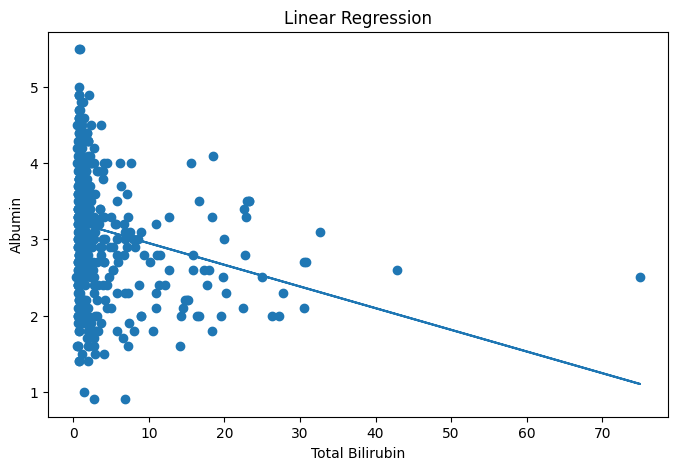

In [ ]:
# Regression Plot

plt.figure(figsize=(8,5))

plt.scatter(
    df['Total_Bilirubin'],
    df['Albumin']
)

plt.plot(
    df['Total_Bilirubin'],
    model.predict(X)
)

plt.xlabel("Total Bilirubin")

plt.ylabel("Albumin")

plt.title("Linear Regression")

plt.show()

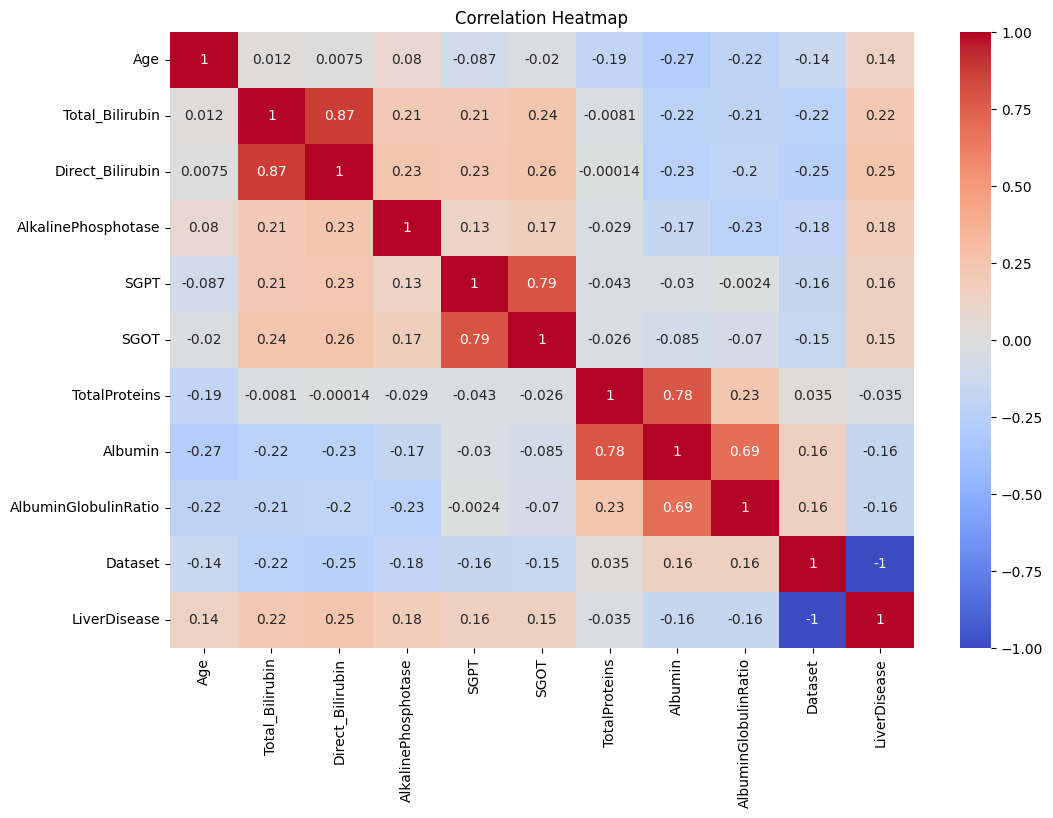

In [ ]:
# Question 18: Heatmap, Scatter Matrix, Pairplot
# Correlation Heatmap

import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(12,8))

sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    cmap='coolwarm'
)

plt.title("Correlation Heatmap")

plt.show()

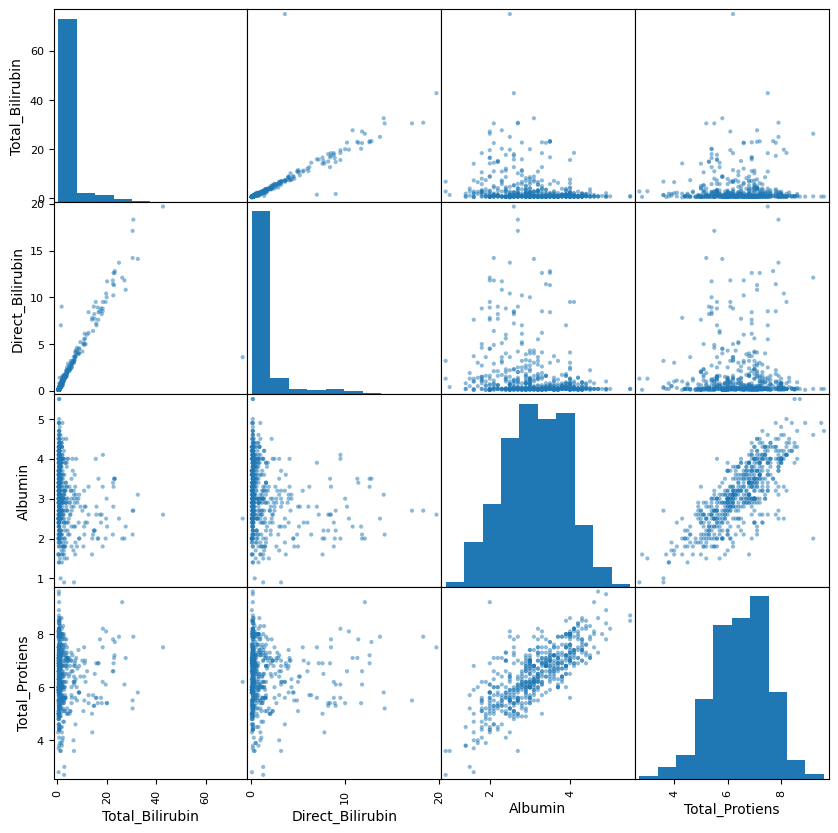

In [ ]:
# Scatter Matrix

from pandas.plotting import scatter_matrix

scatter_matrix(
    df[
        [
            'Total_Bilirubin',
            'Direct_Bilirubin',
            'Albumin',
            'Total_Protiens'
        ]
    ],
    figsize=(10,10)
)

plt.show()



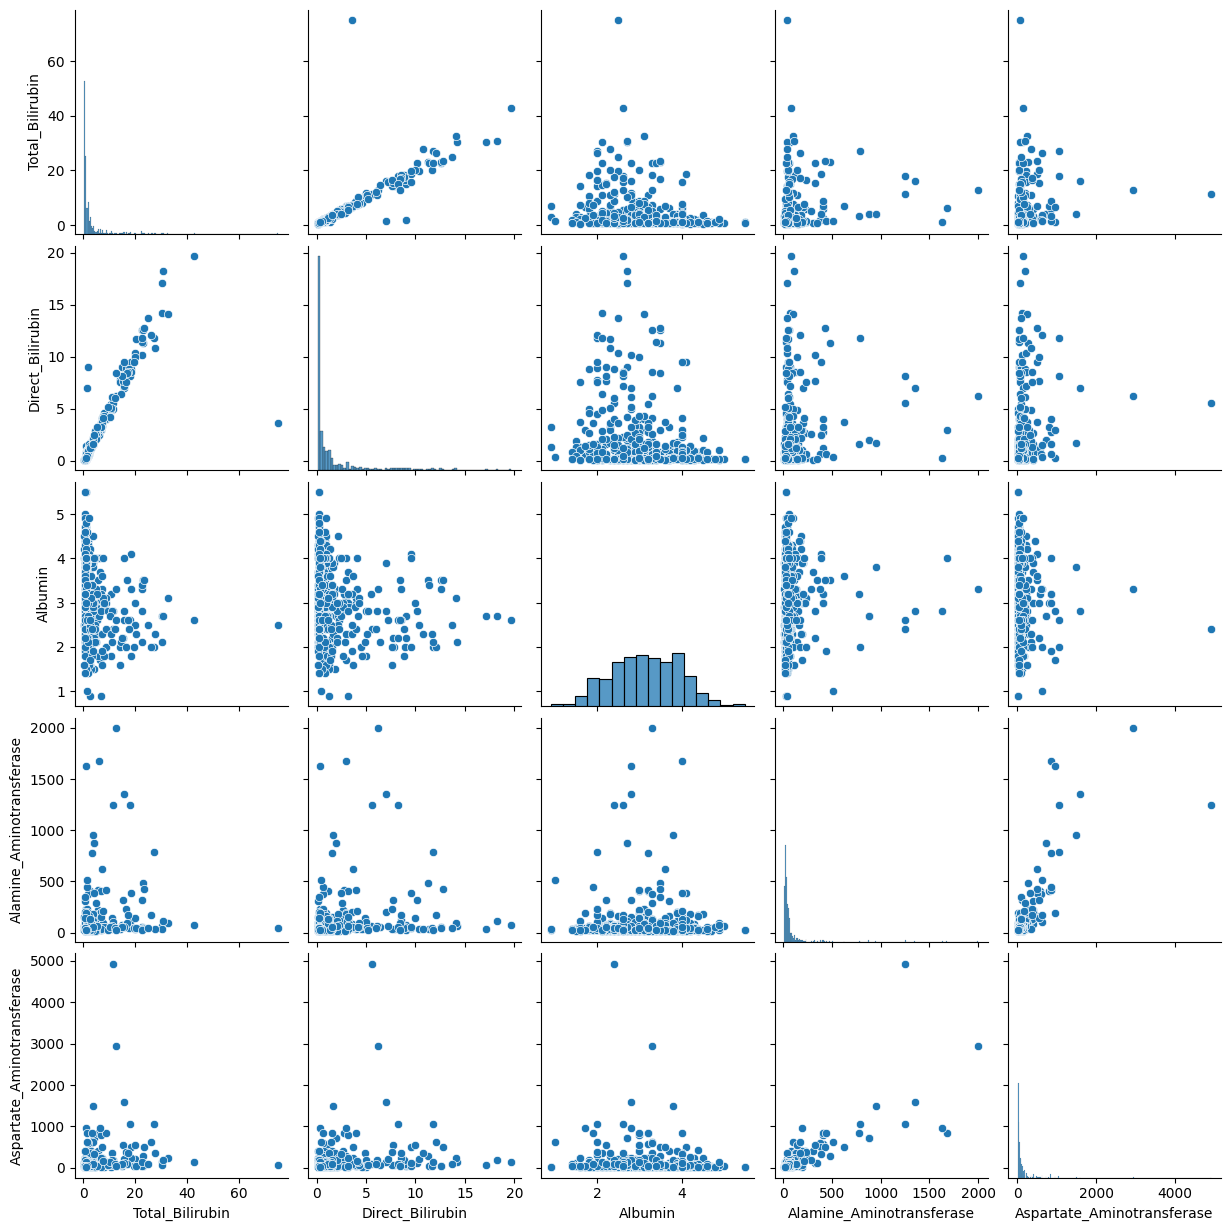

In [ ]:
# Pairplot

sns.pairplot(
    df[
        [
            'Total_Bilirubin',
            'Direct_Bilirubin',
            'Albumin',
            'Alamine_Aminotransferase',
            'Aspartate_Aminotransferase'
        ]
    ]
)

plt.show()

In [ ]:
# Question 19: Hypothesis Testing

from scipy.stats import ttest_ind

liver = df[df['Dataset']==1]

non_liver = df[df['Dataset']==0]

In [ ]:
# Bilirubin

t,p = ttest_ind(
    liver['Total_Bilirubin'],
    non_liver['Total_Bilirubin']
)

print("Bilirubin")
print("t =",t)
print("p =",p)

Bilirubin
t = 5.422946004172417
p = 8.632557516910643e-08


In [ ]:
# Albumin

t,p = ttest_ind(
    liver['Albumin'],
    non_liver['Albumin']
)

print("Albumin")
print("t =",t)
print("p =",p)

Albumin
t = -3.887737187533294
p = 0.00011294110862439262


In [ ]:
# SGPT

t,p = ttest_ind(
    liver['Alamine_Aminotransferase'],
    non_liver['Alamine_Aminotransferase']
)

print("SGPT")
print("t =",t)
print("p =",p)

SGPT
t = 3.9713932788569575
p = 8.048745092309299e-05


In [ ]:
# SGOT

t,p = ttest_ind(
    liver['Aspartate_Aminotransferase'],
    non_liver['Aspartate_Aminotransferase']
)

print("SGOT")
print("t =",t)
print("p =",p)

SGOT
t = 3.6899707510939326
p = 0.0002455184341048781


In [ ]:
# Question 20: Probability

P_Liver = len(liver)/len(df)

print("P(Liver Disease) =",P_Liver)

P(Liver Disease) = 0.7150259067357513


In [ ]:
# Bayes theorem

high_bili = df[
    df['Total_Bilirubin']
    >
    df['Total_Bilirubin'].mean()
]

P_HighBili = len(high_bili)/len(df)

P_HighBili_given_Liver = len(
    liver[
        liver['Total_Bilirubin']
        >
        df['Total_Bilirubin'].mean()
    ]
)/len(liver)

P_Liver = len(liver)/len(df)

P_Liver_given_HighBili = (
    P_HighBili_given_Liver *
    P_Liver
)/P_HighBili

print(
"P(Liver Disease | High Bilirubin) =",
P_Liver_given_HighBili
)

P(Liver Disease | High Bilirubin) = 0.9565217391304348


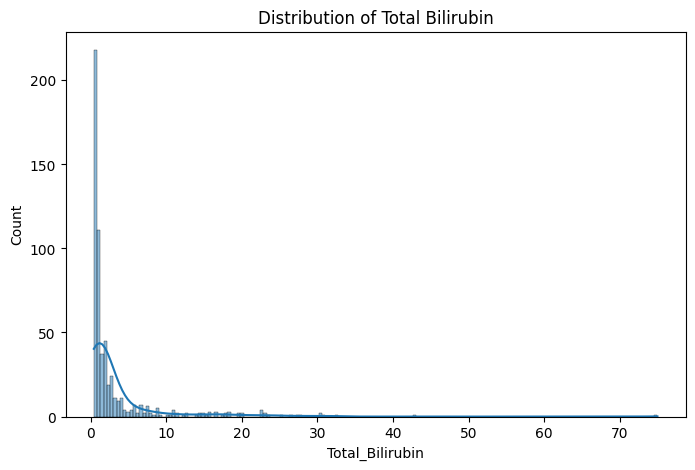

In [ ]:
# Distribution Analysis + CLT

plt.figure(figsize=(8,5))

sns.histplot(
    df['Total_Bilirubin'],
    kde=True
)

plt.title("Distribution of Total Bilirubin")

plt.show()

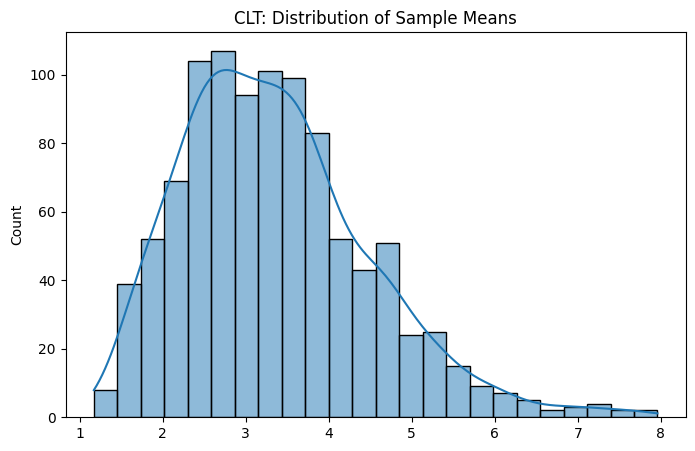

In [ ]:
# CLT Demonstration

sample_means = []

for i in range(1000):

    sample = df['Total_Bilirubin'].sample(
        30,
        replace=True
    )

    sample_means.append(sample.mean())

plt.figure(figsize=(8,5))

sns.histplot(
    sample_means,
    kde=True
)

plt.title("CLT: Distribution of Sample Means")

plt.show()

In [ ]:
# Confidence Interval

from scipy import stats

mean = np.mean(df['Total_Bilirubin'])

sem = stats.sem(df['Total_Bilirubin'])

ci = stats.t.interval(
    0.95,
    len(df)-1,
    loc=mean,
    scale=sem
)

print("95% Confidence Interval =", ci)

95% Confidence Interval = (np.float64(2.807038690931542), np.float64(3.823703968826661))


In [ ]:
print("""
Key Findings:

1. Strong positive correlation between:
   - Total Bilirubin and Direct Bilirubin
   - SGPT and SGOT

2. Higher bilirubin is associated with lower albumin.

3. Liver disease patients show significantly
   different bilirubin, albumin, SGPT and SGOT levels.

4. High bilirubin greatly increases the probability
   of liver disease.

5. Statistical analysis, regression,
   confidence intervals and hypothesis testing
   consistently support liver disease prediction.

Major Risk Factors:
- High Bilirubin
- High Direct Bilirubin
- High SGPT
- High SGOT
- Low Albumin
- Low A/G Ratio

Recommendation:
Regular liver screening and early diagnosis
can improve patient outcomes.
""")


Key Findings:

1. Strong positive correlation between:
   - Total Bilirubin and Direct Bilirubin
   - SGPT and SGOT

2. Higher bilirubin is associated with lower albumin.

3. Liver disease patients show significantly
   different bilirubin, albumin, SGPT and SGOT levels.

4. High bilirubin greatly increases the probability
   of liver disease.

5. Statistical analysis, regression,
   confidence intervals and hypothesis testing
   consistently support liver disease prediction.

Major Risk Factors:
- High Bilirubin
- High Direct Bilirubin
- High SGPT
- High SGOT
- Low Albumin
- Low A/G Ratio

Recommendation:
Regular liver screening and early diagnosis
can improve patient outcomes.

